# Module 2 · Metabolic Networks and Mass Balances
**25 minutes: principles 6 · example 6 · exercises 10 · discussion 3**

[Course introduction](00_Introduction.ipynb)

**Learning objectives:** translate reaction stoichiometry into concentration derivatives,
verify local carbon conservation, and distinguish changes in individual fluxes from changes
in net assimilation.

[Reference answers with runnable code](#reference-answer) are included at the end of this notebook.


In [ ]:
# Locate c3_model for both local Jupyter and Kaggle sessions.
import sys
from pathlib import Path

_model_root = None
for _candidate in (Path.cwd(), *Path.cwd().parents):
    if (_candidate / "c3_model" / "__init__.py").is_file():
        _model_root = _candidate
        break

if _model_root is None:
    _matches = sorted(Path("/kaggle/input").glob("**/c3_model/__init__.py"))
    if _matches:
        _model_root = _matches[0].parent.parent

if _model_root is None:
    raise FileNotFoundError(
        "Cannot find c3_model/__init__.py. On Kaggle, add the dataset containing "
        "the complete c3_model folder via Add Input. Locally, start Jupyter "
        "from the project folder or its Course subfolder."
    )

if str(_model_root) not in sys.path:
    sys.path.insert(0, str(_model_root))
print("c3_model directory:", _model_root / "c3_model")


## 1. Principles · 6 min
Rate equations determine reaction fluxes; stoichiometry determines how those fluxes change pools:
$$\frac{d\mathbf{x}}{dt}=N\mathbf{v}(\mathbf{x}).$$
A column of $N$ describes one reaction. Substrates have negative coefficients and products
positive coefficients. For example, the source network has $d[SBP]/dt=v_8-v_9$.

Add a teaching reaction parallel to FBA: **2 T3P → FBP**. Its contributions are
$$\Delta\dot{[T3P]}=-2v_{new},\qquad\Delta\dot{[FBP]}=v_{new}.$$
T3P contains three carbon atoms and FBP six, so $3(-2v_{new})+6v_{new}=0$.
Adding product without consuming the corresponding substrate would create carbon.

This is a programming exercise, not an experimentally validated engineering bypass.
Local carbon conservation alone does not demonstrate enzyme availability, thermodynamic
feasibility, correct compartmentation or a complete energetic mechanism.

The whole network is open: fixation, photorespiratory CO₂ release, starch formation, sucrose
export and PGA utilization cross its boundary. The whole-network check therefore accounts
for those boundary fluxes; it does not require all carbon pools to remain constant.

## 2. Worked example · 6 min
Run the cell below. Compare the circular carbon skeleton, net assimilation, substrate/product
pools and reaction fluxes. The diagram omits secondary substrates and other pathway branches;
the differential equations, not the diagram, define the complete stoichiometry.

Local carbon-balance residual of the added reaction: 0.00e+00 mM C/s
Net A: baseline=15.558; modified=15.613 µmol CO₂ m⁻² s⁻¹


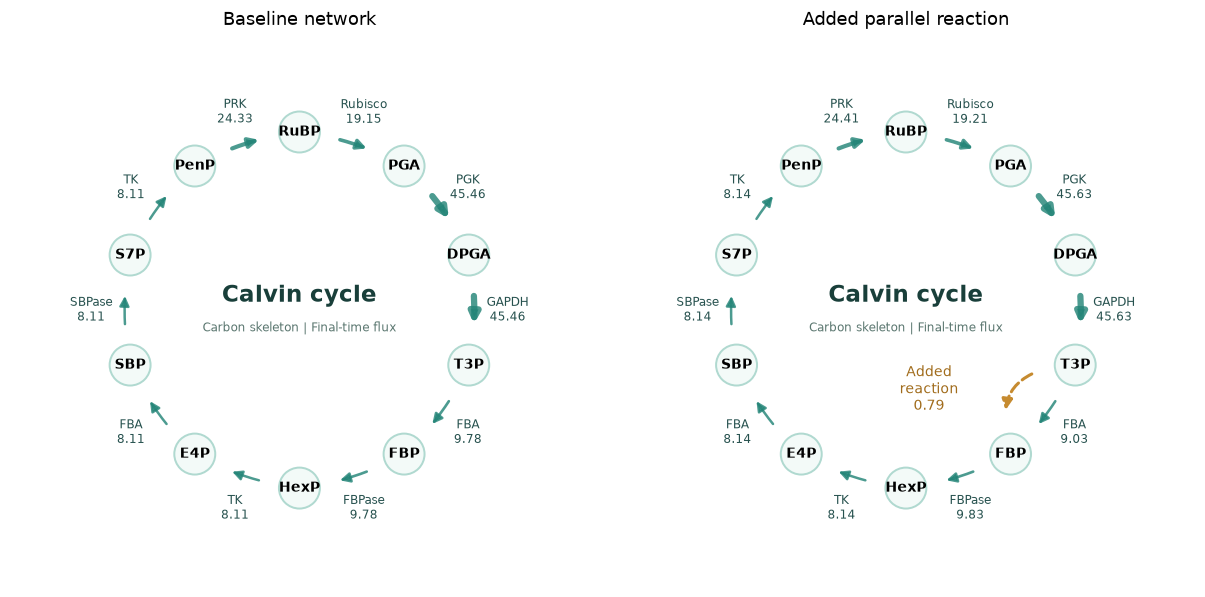

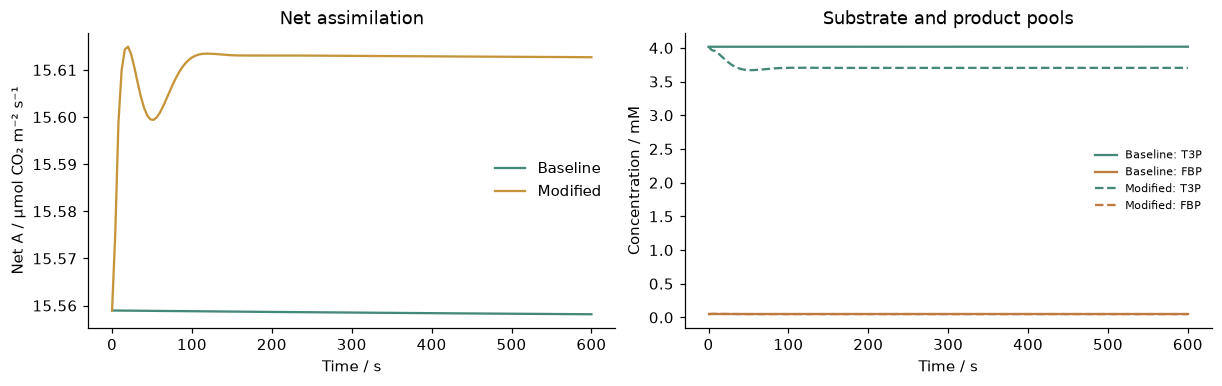

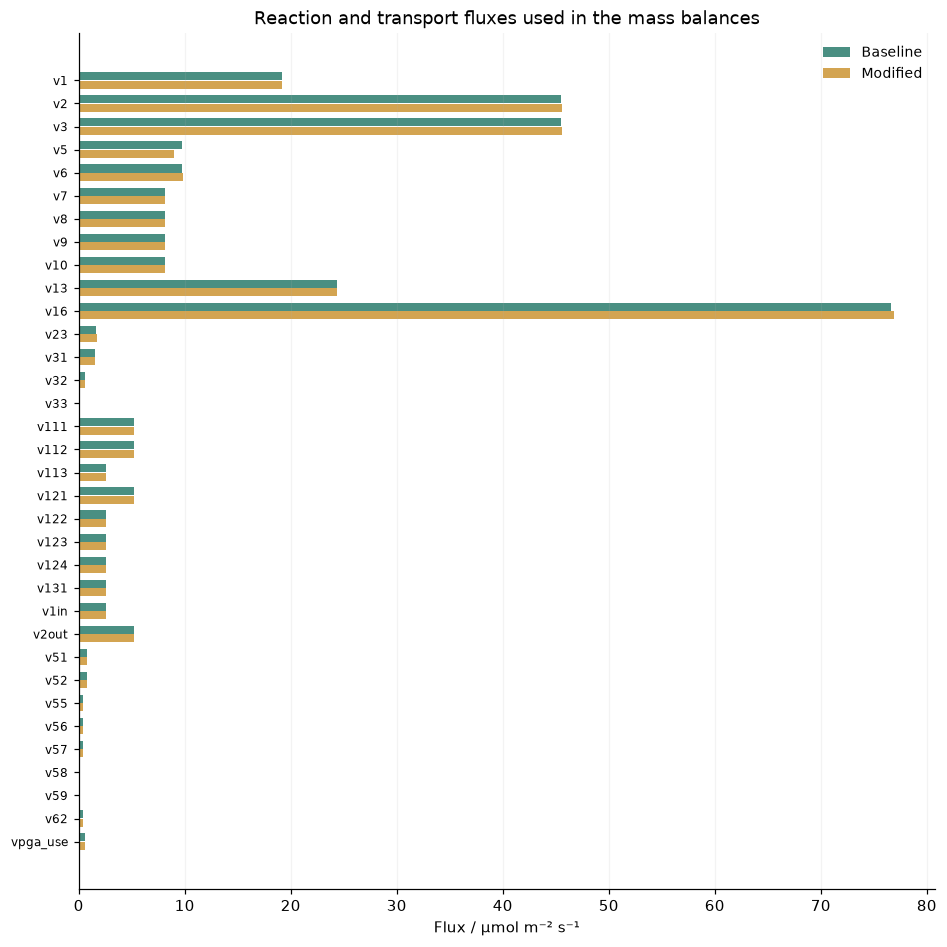

Added reaction flux: 0.793 µmol m⁻² s⁻¹, reported separately from the original 41 output slots.


In [ ]:
from c3_model import C3Model, simulate, STATE_NAMES
from c3_model.plots import style, pathway, flux_comparison
import numpy as np
import matplotlib.pyplot as plt
style()

vmax_new = 0.03  # EDIT: added reaction capacity, mM/s; zero recovers the baseline
km_new = 0.5    # EDIT: apparent substrate constant, mM
def new_rate(t3p):
    return vmax_new * t3p / (km_new + t3p)  # EDIT: your reaction rate law

class DesignedC3(C3Model):
    def rhs(self, t, y):
        dy = super().rhs(t, y)
        rate = new_rate(y[STATE_NAMES.index('T3P')])
        dy[STATE_NAMES.index('T3P')] -= 2 * rate
        dy[STATE_NAMES.index('FBP')] += rate
        return dy

warm = simulate(C3Model(), 3000).states[-1]
base_model, changed_model = C3Model(), DesignedC3()
base = simulate(base_model, 600, initial=warm)
changed = simulate(changed_model, 600, initial=warm)
addition = changed_model.rhs(0, warm) - base_model.rhs(0, warm)
carbon = np.zeros(35)
carbon[STATE_NAMES.index('T3P')] = 3
carbon[STATE_NAMES.index('FBP')] = 6
residual = float(carbon @ addition)
assert abs(residual) < 1e-12, 'The added reaction is not locally carbon-balanced. Check the coefficients.'
print(f'Local carbon-balance residual of the added reaction: {residual:.2e} mM C/s')
print(f'Net A: baseline={base.assimilation[-1]:.3f}; modified={changed.assimilation[-1]:.3f} µmol CO₂ m⁻² s⁻¹')

fig, axes = plt.subplots(1, 2, figsize=(11, 5.3), constrained_layout=True)
pathway(axes[0], base.fluxes[-1]); axes[0].set_title('Baseline network')
added_flux = 30 * new_rate(changed.concentration('T3P')[-1])
pathway(axes[1], changed.fluxes[-1], added=added_flux); axes[1].set_title('Added parallel reaction')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
axes[0].plot(base.time, base.assimilation, label='Baseline', color='#438879')
axes[0].plot(changed.time, changed.assimilation, label='Modified', color='#c69539')
axes[0].set(xlabel='Time / s', ylabel='Net A / µmol CO₂ m⁻² s⁻¹', title='Net assimilation')
axes[0].legend(frameon=False)
for run, prefix, ls in [(base, 'Baseline', '-'), (changed, 'Modified', '--')]:
    for name, color in [('T3P', '#438879'), ('FBP', '#bd7b3e')]:
        axes[1].plot(run.time, run.concentration(name), ls=ls, color=color, label=f'{prefix}: {name}')
axes[1].set(xlabel='Time / s', ylabel='Concentration / mM', title='Substrate and product pools')
axes[1].legend(frameon=False, fontsize=7)
plt.show()
fig, ax = plt.subplots(figsize=(8.5, 8.5), constrained_layout=True)
flux_comparison(ax, base.fluxes[-1], changed.fluxes[-1])
plt.show()
print(f'Added reaction flux: {added_flux:.3f} µmol m⁻² s⁻¹, reported separately from the original 41 output slots.')

*Diagram note:* arrow values are final-time fluxes in µmol m⁻² s⁻¹. The carbon skeleton
omits secondary substrates, photorespiration and sucrose branches. Reserved entries,
diagnostic import rates and buffered-cofactor exchange are not presented as additional
operative network reactions.

## 3. Exercises · 10 min
Use the hints when you need them. Write your own code and explanations before checking
the reference answers at the end of this notebook.

### 2A · Stoichiometry · 3 min
Complete `added_balance(rate)` for the teaching reaction **2 T3P → FBP**.
The function must return two concentration-change rates in the order **[T3P, FBP]**.

**Step-by-step hints**

1. Treat `rate` as the number of reaction events per unit volume and time, in mM/s.
   It is an input to the function; you do not need to write a kinetic equation here.
2. Read the arrow: T3P is consumed, so its change must be negative. FBP is produced,
   so its change must be positive. Count how many molecules of each are involved.
3. Multiply each signed stoichiometric coefficient by `rate`. Put the two expressions
   into `t3p_change` and `fbp_change` in the code cell below.
4. Python writes a two-item list as `[first_value, second_value]`. The return statement
   is supplied; keep the order [T3P, FBP].
5. Run the cell at `rate = 0.2`. The supplied checks test both the coefficients and
   carbon conservation. If it prints “Not yet completed”, one of the two TODOs is still `None`.

**Self-check:** the first value should be negative, the second positive, and a zero
reaction rate should give two zeros. T3P has 3 carbons and FBP has 6. Check
`3 × t3p_change + 6 × fbp_change`, rather than adding the two molecule-change rates.
The weighted result has units **mM C/s**; the two returned values have units **mM/s**.

### 2B · Controlled comparison · 4 min
Compare added capacities of **0, 0.03 and 0.06 mM/s** and record the final outputs.

**Where to edit and what to run**

1. Find `vmax_new = 0.03` near the top of the worked-example code cell above. Change
   only that value for each treatment. Keep `km_new = 0.5`, the reaction law,
   environmental settings and the `warm` initialization unchanged.
2. Run the **entire worked-example cell** after each edit. Editing a number does not
   update the existing `changed` result or its saved figures until you run the cell.
3. The code passes the same `warm` array to baseline and treatment through `initial=warm`.
   This makes the comparison start from the same metabolite pools.
4. Read exact endpoint values using `[-1]`, which selects the last recorded time.
   Add these lines at the bottom of the worked-example cell if you need them:

```python
a_final = changed.assimilation[-1]
t3p_final = changed.concentration('T3P')[-1]
print(f'Vmax_new={vmax_new:.2f}; net A={a_final:.4f}; T3P={t3p_final:.4f}')
print(f'Change in net A={a_final - base.assimilation[-1]:+.4f}')
```

Record your results before moving to the next capacity. Use the printed numbers;
the plots help you interpret the response over time.

| Added Vmax / mM s⁻¹ | Net A at 600 s / µmol CO₂ m⁻² s⁻¹ | T3P at 600 s / mM | Change in net A versus baseline |
|---:|---|---|---|
| 0.00 | Fill in | Fill in | Fill in |
| 0.03 | Fill in | Fill in | Fill in |
| 0.06 | Fill in | Fill in | Fill in |

**Zero-control hint:** at `vmax_new = 0`, the added reaction rate is zero. The modified
trajectory should then match the baseline. You can add this guarded check to the example:

```python
if vmax_new == 0:
    np.testing.assert_allclose(changed.states, base.states, rtol=1e-12, atol=1e-12)
```

Compare the computed changes in net A with the changes in T3P. You do not need to make
every treatment improve assimilation. These are model responses from the stated initial
condition; a 600-s endpoint is not proof that all pools have reached steady state.

### 2C · Carbon accounting and interpretation · 3 min
Suppose the T3P coefficient is incorrectly set to **−1**, while the FBP coefficient
remains **+1**. Calculate the carbon residual at `rate = 0.2 mM/s`.

**Calculation hints**

1. Write the incorrect pair of pool-change rates from those coefficients.
2. Multiply the T3P change by 3 carbon atoms and the FBP change by 6.
3. Add the two carbon contributions. Keep the signs and state the unit, mM C/s.

| Pool | Carbon atoms per molecule | Incorrect coefficient | Pool-change rate at 0.2 mM/s | Carbon contribution |
|---|---:|---:|---|---|
| T3P | 3 | −1 | Fill in | Fill in |
| FBP | 6 | +1 | Fill in | Fill in |

**Interpretation hints:** a positive residual indicates artificial carbon creation;
a negative residual indicates unaccounted carbon removal. A zero local residual checks
this reaction's carbon bookkeeping. The whole network also has fixation, carbon exports
and other boundary fluxes, so its total carbon pools need not stay constant.

Finish with two short explanations: why the incorrect coefficient breaks conservation,
and why even the correct coefficients do not establish biological feasibility. For the
second explanation, discuss at least two of: an enzyme that can catalyse the reaction,
substrate specificity, cellular compartment, thermodynamic direction, or energy/cofactor costs.


In [ ]:
import numpy as np

def added_balance(rate):
    # rate: reaction-event rate in mM/s.
    # Use the reaction 2 T3P -> FBP; consume substrate and produce product.
    t3p_change = None  # TODO: signed T3P coefficient multiplied by rate
    fbp_change = None  # TODO: signed FBP coefficient multiplied by rate
    if t3p_change is None or fbp_change is None:
        return None
    return [t3p_change, fbp_change]  # Required order: [T3P, FBP]

delta = added_balance(0.2)
if delta is None:
    print('Not yet completed: replace both None values in added_balance, then rerun.')
    print('Hint: the T3P term is negative, the FBP term positive; use the reaction coefficients.')
else:
    delta = np.asarray(delta, dtype=float)
    assert delta.shape == (2,), 'Return two values in the order [T3P, FBP].'
    np.testing.assert_allclose(delta, [-0.4, 0.2],
        err_msg='Check each reaction coefficient, its sign, and multiplication by rate.')
    carbon_residual = np.array([3., 6.]) @ delta
    np.testing.assert_allclose(carbon_residual, 0., atol=1e-12,
        err_msg='Check carbon atoms: T3P has 3; FBP has 6.')
    print(f'Exercise 2A passed: contributions={delta} mM/s; carbon residual={carbon_residual:.2e} mM C/s.')


Not yet completed: replace both None values in added_balance, then rerun.
Hint: the T3P term is negative, the FBP term positive; use the reaction coefficients.


## 4. Solutions and discussion · 3 min
[Review solutions 2A–2C](04_Worked_Solutions.ipynb#solution-2).
In the 35-state network, carbon accumulation equals fixation minus photorespiratory CO₂
release and carbon exports. The separately reported Rd is supplied by an external respiratory
reserve and must not be subtracted from these pools again.
Continue to [Module 3](03_Environmental_Responses.ipynb).

<a id="reference-answer"></a>
## Reference answers 2A–2C · Stoichiometry and the network
**2A.** Return `[-2*rate, rate]`. At 0.2 mM/s, the contributions are `[-0.4, 0.2]` mM/s.
The carbon residual is `3*(-0.4) + 6*0.2 = 0` mM C/s.

**2B.** A zero added capacity gives zero added derivatives and must recover the baseline
trajectory at the same initial state. Nonzero capacity redistributes substrate and product;
its effect on assimilation must be obtained from the complete network. The code checks the
zero-capacity control and prints the nonzero-treatment results.

**2C.** Using `[-rate, rate]` incorrectly gives `3*(-0.2) + 6*0.2 = +0.6` mM C/s.
Carbon has been created mathematically. Correct stoichiometry is necessary but does not
demonstrate enzyme existence, substrate specificity, localization, thermodynamic feasibility
or energetic completeness.

Added capacity=0.00 mM/s; net A=15.5582; T3P=4.0179 mM


Added capacity=0.03 mM/s; net A=15.6127; T3P=3.7040 mM


Added capacity=0.06 mM/s; net A=15.6507; T3P=3.4095 mM


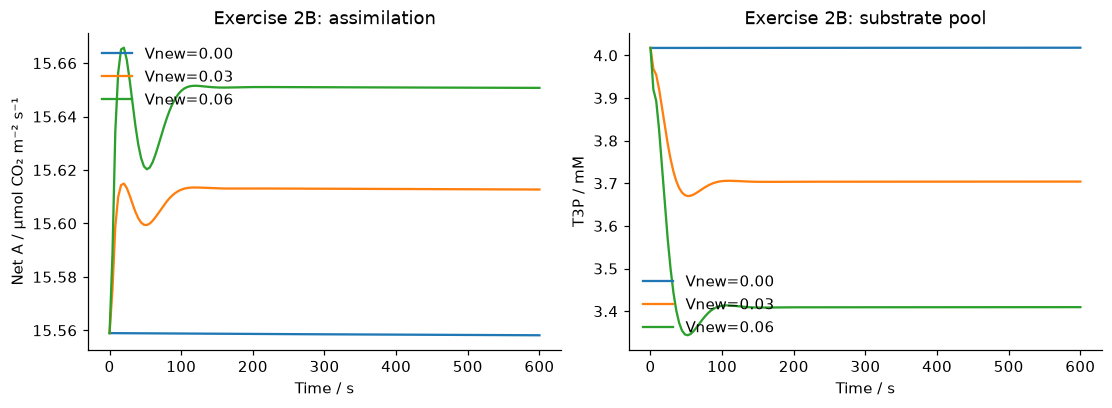

In [ ]:
from c3_model import C3Model, simulate
from c3_model.plots import style
import numpy as np
import matplotlib.pyplot as plt
style()

def added_balance(rate):
    return [-2*rate, rate]
np.testing.assert_allclose(np.array([3, 6]) @ added_balance(.2), 0., atol=1e-12)
class ParallelC3(C3Model):
    def __init__(self, capacity):
        super().__init__()
        self.capacity = capacity
    def rhs(self, t, y):
        dy = super().rhs(t, y)
        rate = self.capacity * y[3] / (.5 + y[3])
        dy[3] -= 2 * rate
        dy[4] += rate
        return dy

warm = simulate(C3Model(), 3000).states[-1]
original = simulate(C3Model(), 600, initial=warm)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for capacity in [0, .03, .06]:
    run = simulate(ParallelC3(capacity), 600, initial=warm)
    if capacity == 0:
        np.testing.assert_allclose(run.states, original.states, rtol=1e-12, atol=1e-12)
    print(f'Added capacity={capacity:.2f} mM/s; net A={run.assimilation[-1]:.4f}; T3P={run.concentration("T3P")[-1]:.4f} mM')
    axes[0].plot(run.time, run.assimilation, label=f'Vnew={capacity:.2f}')
    axes[1].plot(run.time, run.concentration('T3P'), label=f'Vnew={capacity:.2f}')
axes[0].set(xlabel='Time / s', ylabel='Net A / µmol CO₂ m⁻² s⁻¹', title='Exercise 2B: assimilation')
axes[1].set(xlabel='Time / s', ylabel='T3P / mM', title='Exercise 2B: substrate pool')
for ax in axes:
    ax.legend(frameon=False)
plt.show()